In [3]:
%matplotlib ipympl
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import copy
from copy import deepcopy

mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['font.sans-serif'] = 'Arial'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['axes.titlepad'] = 2.
mpl.rcParams['mathtext.default'] = 'regular'


def clean_axes(axes, left=True, right=False):
    """
    Remove top and right axes from pyplot axes object.
    :param axes: list of pyplot.Axes
    :param top: bool
    :param left: bool
    :param right: bool
    """
    if not type(axes) in [np.ndarray, list]:
        axes = [axes]
    elif type(axes) == np.ndarray:
        axes = axes.flatten()
    for axis in axes:
        axis.tick_params(direction='out')
        axis.spines['top'].set_visible(False)
        if not right:
            axis.spines['right'].set_visible(False)
        if not left:
            axis.spines['left'].set_visible(False)
        axis.get_xaxis().tick_bottom()
        axis.get_yaxis().tick_left()


def scaled_single_sigmoid(th, peak, x=None, ylim=None):
    """
    Transform a sigmoid to intersect x and y range limits.
    :param th: float
    :param peak: float
    :param x: array
    :param ylim: pair of float
    :return: callable
    """
    if x is None:
        x = (0., 1.)
    if ylim is None:
        ylim = (0., 1.)
    if th < x[0] or th > x[-1]:
        raise ValueError('scaled_single_sigmoid: th: %.2E is out of range for xlim: [%.2E, %.2E]' % (th, x[0], x[-1]))
    if peak == th:
        raise ValueError('scaled_single_sigmoid: peak and th: %.2E cannot be equal' % th)
    slope = 2. / (peak - th)
    y = lambda x: 1. / (1. + np.exp(-slope * (x - th)))
    start_val = y(x[0])
    end_val = y(x[-1])
    amp = end_val - start_val
    target_amp = ylim[1] - ylim[0]
    return lambda xi: (target_amp / amp) * (1. / (1. + np.exp(-slope * (xi - th))) - start_val) + ylim[0]


def get_linear_W_eq(dt, ET_IS, learning_rate, dep_ratio, max_weight):
    W_eq = np.ones(ET_IS.shape[0])
    W_eq *= 1. / (1. + dep_ratio) * max_weight
    return W_eq


def update_W_cont(dt, ET_IS, w, pot_f, dep_f, learning_rate, dep_ratio, max_weight):
    w_current = np.copy(w)
    for i in range(ET_IS.shape[1]):
        dw_dt = get_dW_dt(ET_IS[:,i], w_current, pot_f, dep_f, learning_rate, dep_ratio, max_weight)
        w_current += dw_dt * dt
        w_current = np.maximum(0., np.minimum(max_weight, w_current))
    return w_current


def get_dW_dt(ET_IS, w, pot_f, dep_f, learning_rate, dep_ratio, max_weight):
    w0 = w / max_weight
    dWdt = learning_rate * ((1. - w0) * pot_f(ET_IS) - dep_ratio * w0 * dep_f(ET_IS))
    dWdt *= max_weight
    return dWdt


def get_sig_W_eq(dt, ET_IS, pot_f, dep_f, learning_rate, dep_ratio, max_weight):
    W_eq = np.empty(ET_IS.shape[0])
    W_eq[:] = np.nan
    numer = np.trapz(pot_f(ET_IS), dx=dt)
    denom = numer + np.trapz(dep_ratio * dep_f(ET_IS), dx=dt)
    indexes = np.where(denom >= 0.001)
    W_eq[indexes] = numer[indexes] / denom[indexes] * max_weight
    return W_eq

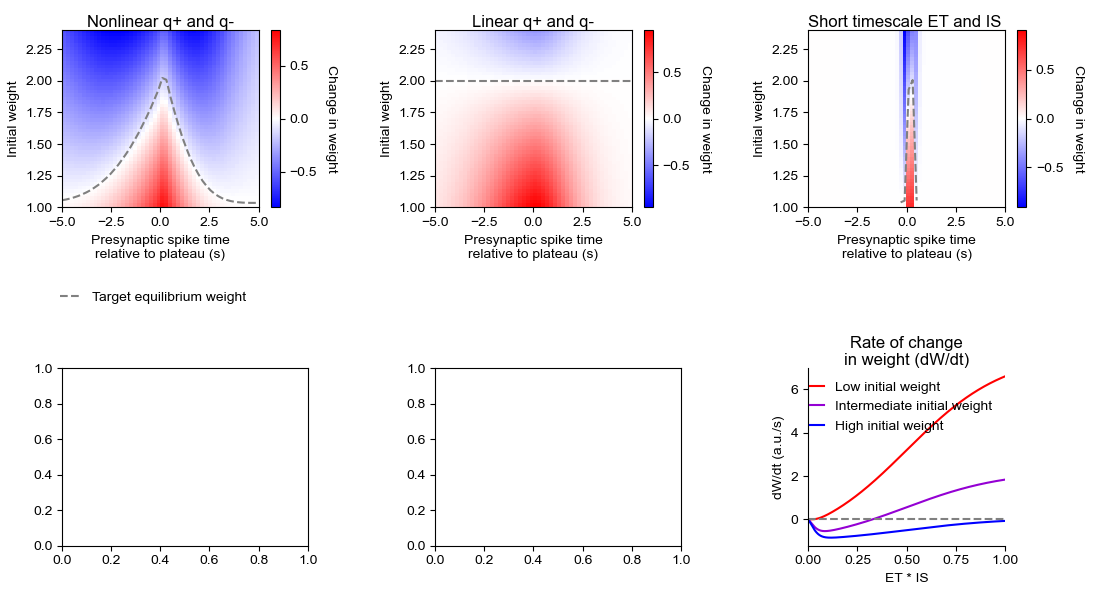

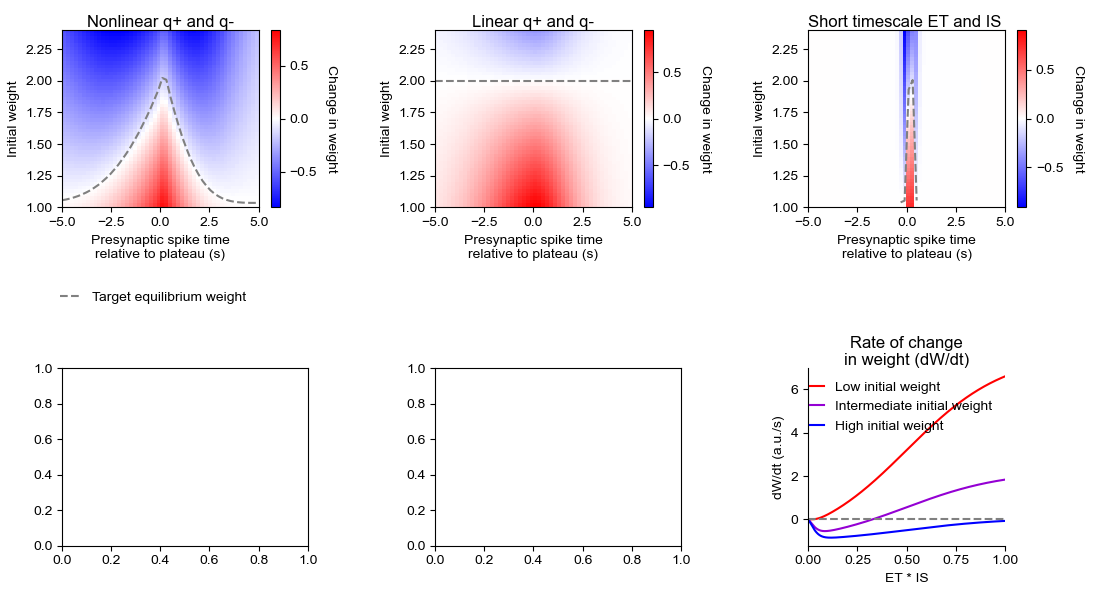

In [4]:
input_dim = 50
t_res = 0.01
tau_ET = 2.5
tau_IS = 1.5
sig_learning_rate = 1.7
sig_dep_ratio = 0.12
sig_max_weight = 5.
sig_dep_th = 0.01
sig_dep_width = 0.045
sig_pot_th = 0.5
sig_pot_width = 0.5

input_locs = np.linspace(-5., 5., input_dim)
t = np.arange(-10., 10., t_res)
pre_activity = np.zeros((input_dim, len(t)))
for i in range(input_dim):
    index = np.where(t >= input_locs[i])[0][0]
    pre_activity[i, index] = 1.

example_input_spike = pre_activity[input_dim//2,:]
plateau = np.zeros_like(t)
plateau_indexes = np.where((t >= 0.) & (t < 0.3))[0]
plateau[plateau_indexes] = 1.

filter_t = np.arange(0., 20., t_res)
filter_ET = np.exp(-filter_t/tau_ET)
filter_ET /= np.sum(filter_ET)
this_ET = np.convolve(example_input_spike, filter_ET)[:len(t)]
ET_norm_factor = np.max(this_ET) / 0.3
this_ET /= ET_norm_factor

filter_IS = np.exp(-filter_t/tau_IS)
filter_IS /= np.sum(filter_IS)
IS = np.convolve(plateau, filter_IS)[:len(t)]
IS /= np.max(IS)

ET = np.empty_like(pre_activity)
for i in range(input_dim):
    ET[i, :] = np.convolve(pre_activity[i, :], filter_ET)[:len(t)] / ET_norm_factor

ET_IS = ET * IS

fig3, axes3 = plt.subplots(2, 3, figsize=(11., 6.))

sig_dW_params = [sig_learning_rate, sig_dep_ratio, sig_max_weight]
sig_dep_f = scaled_single_sigmoid(sig_dep_th, sig_dep_th + sig_dep_width)
sig_pot_f = scaled_single_sigmoid(sig_pot_th, sig_pot_th + sig_pot_width)

sig_W_eq = get_sig_W_eq(t_res, ET_IS, sig_pot_f, sig_dep_f, *sig_dW_params)
sig_dW = np.empty((input_dim, input_dim))
for i, w in enumerate(np.linspace(1., 2.4, input_dim)):
    initial_W = np.ones_like(input_locs) * w
    current_W = np.copy(initial_W)
    for j in range(3):
        current_W = update_W_cont(t_res, ET_IS, current_W, sig_pot_f, sig_dep_f, *sig_dW_params)
    sig_dW[i, :] = np.subtract(current_W, initial_W)

vmax = max(np.abs(np.max(sig_dW)), np.abs(np.min(sig_dW)))
im = axes3[0][0].imshow(sig_dW[::-1, :], extent=(-5., 5., 1., 2.4), aspect='auto', cmap='bwr', vmin=-vmax, vmax=vmax)
cbar = fig3.colorbar(im, ax=axes3[0][0])
cbar.set_label('Change in weight', rotation=270., labelpad=15)
axes3[0][0].plot(input_locs, sig_W_eq, '--', c='grey', label='Target equilibrium weight')
axes3[0][0].legend(frameon=False, bbox_to_anchor=(1., -0.4), handlelength=1.5)
axes3[0][0].set_title('Nonlinear q+ and q-')
axes3[0][0].set_xlabel('Presynaptic spike time\nrelative to plateau (s)')
axes3[0][0].set_ylabel('Initial weight')
axes3[0][0].set_ylim(1., 2.4)

ET_IS_range = np.linspace(0., 1., 1000)
this_sig_dW_dt_low_W0 = get_dW_dt(ET_IS_range, 1., sig_pot_f, sig_dep_f, *sig_dW_params)
axes3[1][2].plot(ET_IS_range, this_sig_dW_dt_low_W0, c='r', label='Low initial weight')

this_sig_dW_dt_low_W0 = get_dW_dt(ET_IS_range, 3.5, sig_pot_f, sig_dep_f, *sig_dW_params)
axes3[1][2].plot(ET_IS_range, this_sig_dW_dt_low_W0, c='darkviolet', label='Intermediate initial weight')

this_sig_dW_dt_high_W0 = get_dW_dt(ET_IS_range, 4.5, sig_pot_f, sig_dep_f, *sig_dW_params)
axes3[1][2].plot(ET_IS_range, this_sig_dW_dt_high_W0, c='b', label='High initial weight')
axes3[1][2].plot(ET_IS_range, np.zeros_like(ET_IS_range), '--', c='grey')
sm = plt.cm.ScalarMappable()
sm.set_array([])
fig3.colorbar(sm, ax=axes3[1][2]).ax.set_visible(False)
axes3[1][2].set_xlim(0., 1.)
axes3[1][2].set_xlabel('ET * IS')
axes3[1][2].set_ylabel('dW/dt (a.u./s)')
axes3[1][2].set_title('Rate of change\nin weight (dW/dt)')
axes3[1][2].legend(loc='best', frameon=False, handlelength=1)
clean_axes(axes3[1][2])


lin_learning_rate = 3.5
lin_dep_ratio = 0.5
lin_max_weight = 3.
tau_ET = 1.5
tau_IS = 1.
lin_dW_params = [lin_learning_rate, lin_dep_ratio, lin_max_weight]
lin_pot_f = lambda x: x
lin_dep_f = lambda x: x

filter_ET = np.exp(-filter_t / tau_ET)
filter_ET /= np.sum(filter_ET)
this_ET = np.convolve(example_input_spike, filter_ET)[:len(t)]
ET_norm_factor = np.max(this_ET) / 0.3
this_ET /= ET_norm_factor

filter_IS = np.exp(-filter_t / tau_IS)
filter_IS /= np.sum(filter_IS)
IS = np.convolve(plateau, filter_IS)[:len(t)]
IS /= np.max(IS)

ET = np.empty_like(pre_activity)
for i in range(input_dim):
    ET[i, :] = np.convolve(pre_activity[i, :], filter_ET)[:len(t)] / ET_norm_factor

ET_IS = ET * IS

linear_W_eq = get_linear_W_eq(t_res, ET_IS, *lin_dW_params)
linear_dW = np.empty((input_dim, input_dim))
for i, w in enumerate(np.linspace(1., 2.4, input_dim)):
    initial_W = np.ones_like(input_locs) * w
    current_W = np.copy(initial_W)
    for j in range(3):
        current_W = update_W_cont(t_res, ET_IS, current_W, lin_pot_f, lin_dep_f, *lin_dW_params)
    linear_dW[i, :] = np.subtract(current_W, initial_W)

vmax = max(np.abs(np.max(linear_dW)), np.abs(np.min(linear_dW)))
im = axes3[0][1].imshow(linear_dW[::-1, :], extent=(-5., 5., 1., 2.4), aspect='auto', cmap='bwr', vmin=-vmax, vmax=vmax)
cbar = fig3.colorbar(im, ax=axes3[0][1])
cbar.set_label('Change in weight', rotation=270., labelpad=15)
axes3[0][1].plot(input_locs, linear_W_eq, '--', c='grey', label='Target equilibrium weight')
axes3[0][1].set_title('Linear q+ and q-')
axes3[0][1].set_xlabel('Presynaptic spike time\nrelative to plateau (s)')
axes3[0][1].set_ylabel('Initial weight')


sig_learning_rate = 25.
sig_dep_ratio = 0.12
sig_max_weight = 5.
sig_dep_th = 0.01
sig_dep_width = 0.045
sig_pot_th = 0.5
sig_pot_width = 0.5
tau_ET = 0.1
tau_IS = 0.1
sig_dW_params = [sig_learning_rate, sig_dep_ratio, sig_max_weight]
sig_dep_f = scaled_single_sigmoid(sig_dep_th, sig_dep_th + sig_dep_width)
sig_pot_f = scaled_single_sigmoid(sig_pot_th, sig_pot_th + sig_pot_width)

filter_ET = np.exp(-filter_t / tau_ET)
filter_ET /= np.sum(filter_ET)
this_ET = np.convolve(example_input_spike, filter_ET)[:len(t)]
ET_norm_factor = np.max(this_ET) / 0.3
this_ET /= ET_norm_factor

filter_IS = np.exp(-filter_t / tau_IS)
filter_IS /= np.sum(filter_IS)
IS = np.convolve(plateau, filter_IS)[:len(t)]
IS /= np.max(IS)

ET = np.empty_like(pre_activity)
for i in range(input_dim):
    ET[i, :] = np.convolve(pre_activity[i, :], filter_ET)[:len(t)] / ET_norm_factor

ET_IS = ET * IS

sig_W_eq = get_sig_W_eq(t_res, ET_IS, sig_pot_f, sig_dep_f, *sig_dW_params)
sig_dW = np.empty((input_dim, input_dim))
for i, w in enumerate(np.linspace(1., 2.4, input_dim)):
    initial_W = np.ones_like(input_locs) * w
    current_W = np.copy(initial_W)
    for j in range(3):
        current_W = update_W_cont(t_res, ET_IS, current_W, sig_pot_f, sig_dep_f, *sig_dW_params)
    sig_dW[i, :] = np.subtract(current_W, initial_W)

vmax = max(np.abs(np.max(sig_dW)), np.abs(np.min(sig_dW)))
im = axes3[0][2].imshow(sig_dW[::-1, :], extent=(-5., 5., 1., 2.4), aspect='auto', cmap='bwr', vmin=-vmax, vmax=vmax)
cbar = fig3.colorbar(im, ax=axes3[0][2])
cbar.set_label('Change in weight', rotation=270., labelpad=15)
axes3[0][2].plot(input_locs, sig_W_eq, '--', c='grey', label='Target equilibrium weight')
axes3[0][2].set_title('Short timescale ET and IS', loc='left')
axes3[0][2].set_xlabel('Presynaptic spike time\nrelative to plateau (s)')
axes3[0][2].set_ylabel('Initial weight')
axes3[0][2].set_ylim(1., 2.4)

fig3.tight_layout(w_pad=3., h_pad=3.)
fig3.show()

In [5]:
np.max(ET)

0.3

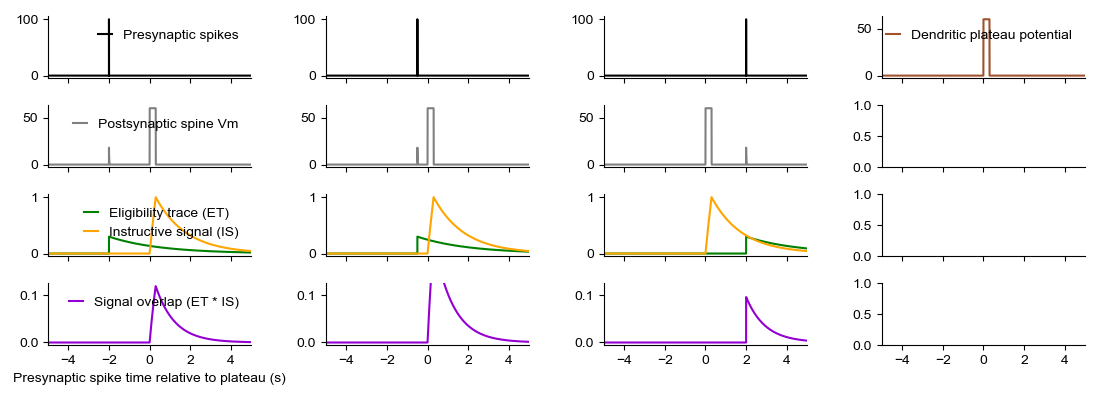

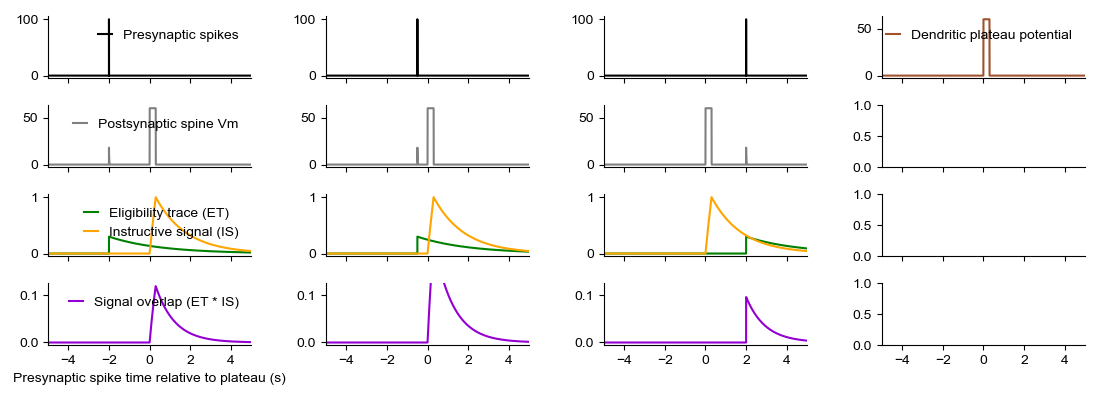

In [6]:
tau_syn = 0.01
fine_t_res = 0.001
fine_t = np.arange(-10., 10., fine_t_res)
fine_example_input_spike = np.zeros_like(fine_t)
fine_example_input_spike[len(fine_t)//2] = 1.
fine_plateau = np.zeros_like(fine_t)
fine_plateau_indexes = np.where((fine_t >= 0.) & (fine_t < 0.3))[0]
fine_plateau[fine_plateau_indexes] = 1.

fine_filter_t = np.arange(0., 20., fine_t_res)
vm_filter = np.exp(-fine_filter_t / tau_syn)
vm_filter /= np.sum(vm_filter)
this_vm = np.convolve(fine_example_input_spike, vm_filter)[:len(fine_t)]
vm_norm_factor = np.max(this_vm) / 0.3

tau_ET = 2.5  # 1.7
tau_IS = 1.5  # 0.9
fine_filter_ET = np.exp(-fine_filter_t / tau_ET)
fine_filter_ET /= np.sum(fine_filter_ET)
this_ET = np.convolve(fine_example_input_spike, fine_filter_ET)[:len(fine_t)]
fine_ET_norm_factor = np.max(this_ET) / 0.3

fine_filter_IS = np.exp(-fine_filter_t / tau_IS)
fine_filter_IS /= np.sum(fine_filter_IS)
fine_IS = np.convolve(fine_plateau, fine_filter_IS)[:len(fine_t)]
fine_IS /= np.max(fine_IS)

fig4, axes4 = plt.subplots(4, 4, figsize=(11., 4.), sharex=True)
axes4[0][3].plot(fine_t, fine_plateau * 60., c='sienna', label='Dendritic plateau potential', linewidth=1.5)
axes4[0][3].legend(loc='best', frameon=False, handlelength=1)
for col, this_input_loc in enumerate([-2., -0.5, 2.]):
    this_spike = np.zeros_like(fine_t)
    this_spike_index = np.where(fine_t >= this_input_loc)[0][0]
    this_spike[this_spike_index] = 1.
    axes4[0][col].plot(fine_t, this_spike * 100., c='k', label='Presynaptic spikes', linewidth=1.5)
    this_vm = np.convolve(this_spike, vm_filter)[:len(fine_t)] / vm_norm_factor
    this_vm = np.maximum(this_vm, fine_plateau)
    axes4[1][col].plot(fine_t, this_vm * 60., c='grey', label='Postsynaptic spine Vm')
    this_ET = np.convolve(this_spike, fine_filter_ET)[:len(fine_t)] / fine_ET_norm_factor
    axes4[2][col].plot(fine_t, this_ET, c='g', label='Eligibility trace (ET)', linewidth=1.5)
    axes4[2][col].plot(fine_t, fine_IS, c='orange', label='Instructive signal (IS)', linewidth=1.5)
    this_ET_IS = this_ET * fine_IS
    axes4[3][col].plot(fine_t, this_ET_IS, c='darkviolet', label='Signal overlap (ET * IS)', linewidth=1.5)

axes4[0][0].set_xlim((-5., 5.))
axes4[0][0].set_xticks(np.arange(-4., 5., 2.))
axes4[0][0].legend(loc='best', frameon=False, handlelength=1)
axes4[1][0].legend(loc='best', frameon=False, handlelength=1)
axes4[2][0].legend(loc='best', frameon=False, handlelength=1)
axes4[3][0].legend(loc='best', frameon=False, handlelength=1)
axes4[3][0].set_xlabel('Presynaptic spike time relative to plateau (s)')
axes4[3][1].sharey(axes4[3][0])
axes4[3][2].sharey(axes4[3][0])

clean_axes(axes4)
fig4.tight_layout(w_pad=3.)
fig4.show()

# EIANN BTSP Variant

In [7]:
import torch

In [8]:
from EIANN.utils import get_scaled_rectified_sigmoid

In [131]:
dep_ratio = 1.
dep_th = 0.01
dep_width = 0.01
q_dep = get_scaled_rectified_sigmoid(dep_th, dep_th + dep_width)
w_max = 2.

def get_dw(ET, w, q_dep, w_max, dep_ratio):
    return (w_max - w.unsqueeze(1)) * ET.unsqueeze(0) - w.unsqueeze(1) * dep_ratio * q_dep(ET).unsqueeze(0)

def get_dw_alt(ET, w, q_dep, w_max, dep_ratio):
    w_eq = get_w_eq(ET, q_dep, w_max, dep_ratio)
    dw = w_eq.unsqueeze(0) - w.unsqueeze(1)
    return dw

def get_dw_alt2(ET, w, q_dep, w_max, dep_ratio):
    dw_orig = get_dw(ET, w, q_dep, w_max, dep_ratio)
    denom = ET + dep_ratio * q_dep(ET)
    valid_indexes = (ET > 0.).nonzero()
    dw = -w.unsqueeze(1).expand(w.shape[0], ET.shape[0])
    dw[:,valid_indexes] = dw_orig[:,valid_indexes] / denom.unsqueeze(0)[:,valid_indexes]
    return dw

def get_w_eq(ET, q_dep, w_max, dep_ratio):
    w_eq = torch.zeros_like(ET)
    valid_indexes = (ET > 0.).nonzero(as_tuple=True)
    w_eq[valid_indexes] = w_max * ET[valid_indexes] / (ET[valid_indexes] + dep_ratio * q_dep(ET[valid_indexes]))
    return w_eq

In [132]:
ET = torch.linspace(0., 1., 1000)
w = torch.linspace(0., w_max, 500)
dw = get_dw(ET, w, q_dep, w_max, dep_ratio)
w_eq = get_w_eq(ET, q_dep, w_max, dep_ratio)
dw_alt = get_dw_alt(ET, w, q_dep, w_max, dep_ratio)
dw_alt2 = get_dw_alt2(ET, w, q_dep, w_max, dep_ratio)

In [116]:
dw.shape

torch.Size([500, 1000])

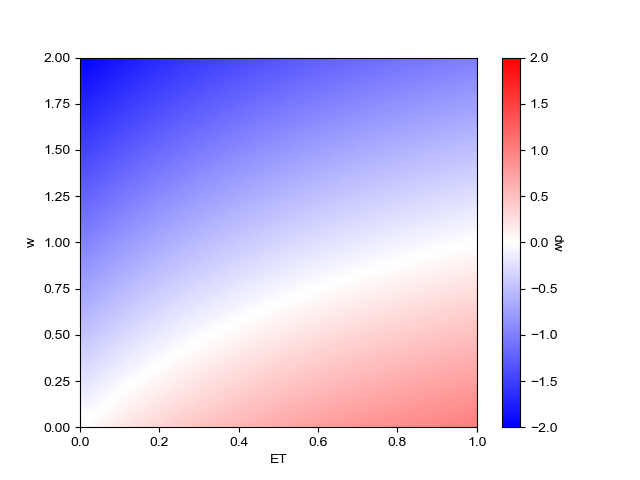

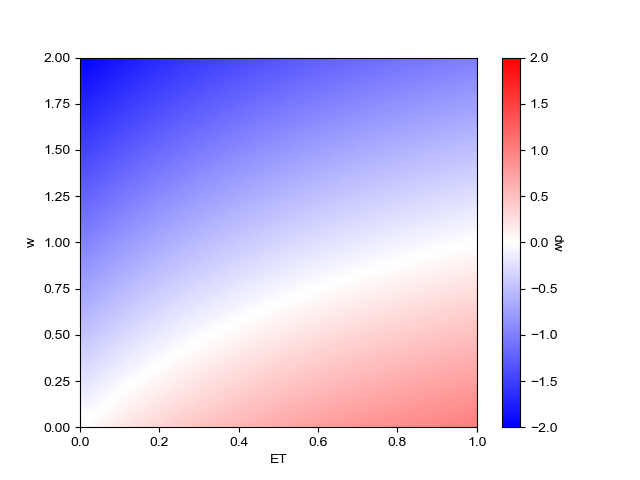

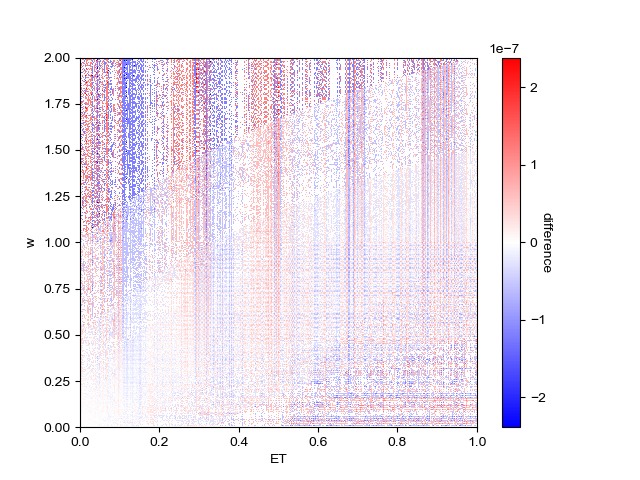

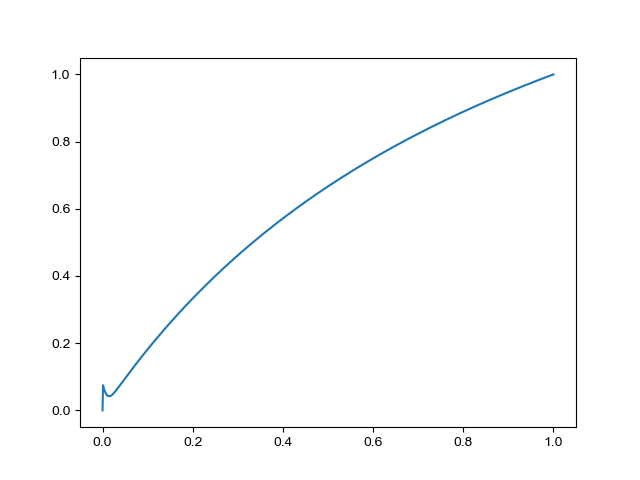

In [133]:
plt.figure()
plt.imshow(dw_alt, aspect='auto', origin='lower', interpolation='none', cmap='bwr', extent=[0., 1., 0., w_max], vmin=-2., vmax=2.)
plt.xlabel('ET')
plt.ylabel('w')
cbar = plt.colorbar()
cbar.set_label(label='dw', rotation=-90.)
plt.show()

plt.figure()
plt.imshow(dw_alt2, aspect='auto', origin='lower', interpolation='none', cmap='bwr', extent=[0., 1., 0., w_max], vmin=-2., vmax=2.)
plt.xlabel('ET')
plt.ylabel('w')
cbar = plt.colorbar()
cbar.set_label(label='dw', rotation=-90.)
plt.show()

plt.figure()
plt.imshow(dw_alt - dw_alt2, aspect='auto', origin='lower', interpolation='none', cmap='bwr', extent=[0., 1., 0., w_max])
plt.xlabel('ET')
plt.ylabel('w')
cbar = plt.colorbar()
cbar.set_label(label='difference', rotation=-90.)
plt.show()

plt.figure()
plt.plot(ET, w_eq)


In [135]:
torch.max(dw_alt - dw_alt2)

tensor(2.3842e-07)

In [119]:
dw.shape

torch.Size([500, 1000])

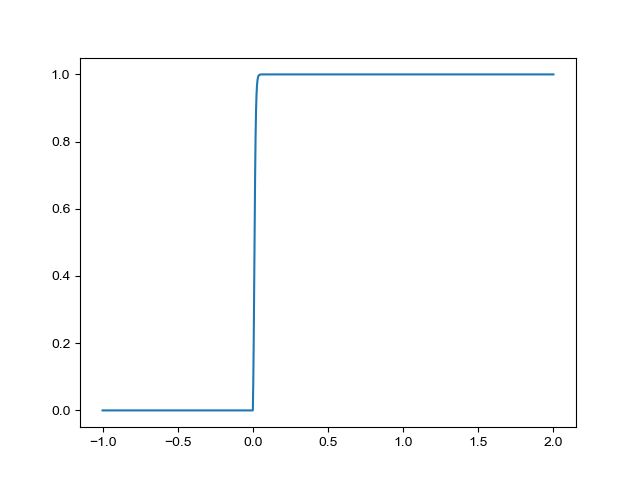

In [120]:
test = torch.linspace(-1., 2, 1000)
plt.figure()
plt.plot(test, q_dep(test))

In [106]:
q_dep(torch.tensor([0.]))

tensor([0.])

In [ ]:
plateau_prob = self.projection.post.plateau.detach().clone()
neg_indexes = (self.projection.post.plateau < 0.).nonzero(as_tuple=True)
plateau_prob[neg_indexes] = 0.
plateau_prob = plateau_prob.unsqueeze(1)

if self.projection.direction in ['forward', 'F']:
    ET = torch.clamp(self.projection.pre.activity, 0., 1.)
elif self.projection.direction in ['recurrent', 'R']:
    ET = torch.clamp(self.projection.pre.prev_activity, 0., 1.)

# pre activity and post plateau for current sample
delta_weight = (plateau_prob *
                ((self.w_max - self.projection.weight) * ET.unsqueeze(0) -
                 self.projection.weight * self.dep_ratio *
                 self.q_dep(ET).unsqueeze(0))).detach().clone()

# neg error - weight update proportional to loss and presynaptic activity
neg_error = self.projection.post.plateau.detach().clone()
neg_error[self.projection.post.plateau > 0.] = 0.
delta_weight += ET.unsqueeze(0) * neg_error.unsqueeze(1)

pos_ET_indexes = (ET > 0.).nonzero(as_tuple=True)
w_eq = torch.zeros_like(ET)
w_eq[pos_ET_indexes] = (self.w_max * ET[pos_ET_indexes]) / (ET[pos_ET_indexes] - self.q_dep(ET[pos_ET_indexes]))
delta_lr_mod = (plateau_prob * ET.unsqueeze(0) *
                self.lr_mod_func(torch.abs(self.projection.weight.data - w_eq.unsqueeze(0))))

self.projection.weight.data += self.learning_rate * self.lr_mod * delta_weight

# elastic learning rate modulation
self.lr_mod += delta_lr_mod
self.lr_mod.clamp_(min=self.elr_min, max=1.)